# MedQA-LoRA, step by step

**What you'll build:** you'll fine-tune a small open model (Qwen2.5-1.5B-Instruct) on medical Q&A twice, with the **same settings and the same number of examples**:

- **Model A** is trained on **raw** data, as scraped.
- **Model B** is trained on **curated** data: cleaned, filtered, deduplicated and balanced.

Then you'll test both, plus the untouched base model, on 150 questions none of them has seen. The question you're answering: **does data quality beat data quantity?**

**Time:** about 3 hours, mostly waiting for the GPU.

| Part | What | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1–4 | Data: load, clean, deduplicate, split | 15 min |
| 5–7 | Training: tokenize, load model, train twice | 45 min |
| 8–9 | Evaluation: generate answers, score them | 30 min |
| 10 | Export to run on your laptop (optional) | 20 min |

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Run the cells **in order**, top to bottom.

---
## Part 0 · Setup

> **Analogy:** setting up the kitchen before you cook. Check the stove works (the GPU), get your ingredients (libraries), and decide where to store leftovers (Google Drive).

### 0.1 Check the GPU
You should see **Tesla T4** in the output. If you see an error, go to Runtime → Change runtime type → T4 GPU.

In [ ]:
!nvidia-smi

Thu Nov 19 06:29:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 0.2 Install libraries
| Library | Job |
|---|---|
| `transformers` | loads Qwen and runs it |
| `peft` | adds the LoRA "sticky notes" |
| `bitsandbytes` | squeezes the model to 4-bit |
| `accelerate` | places the model on the GPU |
| `datasets` | downloads MedQuAD |
| `datasketch` | MinHash for near-duplicate search |
| `rouge_score` | the word-overlap metric |
| `openai` | the LLM judge |

Takes about 2 minutes.

In [ ]:
!pip install -q -U transformers peft bitsandbytes accelerate datasets datasketch rouge_score openai tabulate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


### 0.3 Settings
Every setting lives in this one cell, so both models are guaranteed identical. **Change things here, never inside later cells.**

In [ ]:
import os, re, json, random, unicodedata, gc, math, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- where files go
ROOT = Path("/content/medqa")
DATA, OUT, RES = ROOT / "data", ROOT / "outputs", ROOT / "results"

# ---- data
SEED = 42
TEST_SIZE = 150            # held-out questions, never trained on
TRAIN_SIZE = 2000          # both models get exactly this many examples
MIN_WORDS, MAX_WORDS = 30, 300
NEAR_DUP = 0.8             # Jaccard similarity that counts as "duplicate"
MAX_TYPE_SHARE = 0.20      # no question type over 20% of the curated set

SYSTEM_PROMPT = ("You are a careful medical information assistant. Answer clearly and accurately "
                 "in plain language. You do not diagnose or prescribe; for personal medical "
                 "decisions, advise the user to consult a qualified healthcare professional.")

# ---- model and training
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_LEN = 512              # tokens per example
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
EPOCHS, LR, BATCH, GRAD_ACCUM = 2, 2e-4, 4, 4   # effective batch = 4 x 4 = 16

# ---- evaluation
MAX_NEW_TOKENS = 256
JUDGE_MODEL = "gpt-4.1-mini"   # change if your OpenAI account uses a different model name

random.seed(SEED); np.random.seed(SEED)
print("Settings loaded")

Settings loaded


### 0.4 API key and storage
1. Click the **key icon** on the left, add a secret named `OPENAI_API_KEY` with your key, and switch on **Notebook access**.
2. Allow Google Drive when asked. Free Colab can disconnect, and saving to Drive means your trained models survive it.

In [ ]:
import os
from pathlib import Path
from google.colab import userdata, drive

os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
print("OpenAI key loaded")

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/medqa")
DRIVE.mkdir(parents=True, exist_ok=True)
if not ROOT.exists():
    ROOT.symlink_to(DRIVE)          # /content/medqa now lives on Drive
for d in (DATA, OUT, RES):
    d.mkdir(parents=True, exist_ok=True)
print("Saving everything to", DRIVE)

OpenAI key loaded
Mounted at /content/drive
Saving everything to /content/drive/MyDrive/medqa


---
## Part 1 · Load the data and look at it

> **Analogy:** before cooking, tip the shopping bag out on the counter and look at what you actually bought.

**MedQuAD** is ~16,000 medical question-answer pairs from US National Institutes of Health websites. Each row has a question, an expert answer, and a question type (symptoms, treatment, and so on).

In [ ]:
from datasets import load_dataset

df = load_dataset("keivalya/MedQuad-MedicalQnADataset", split="train").to_pandas()
print(df.columns.tolist(), len(df), "rows")

# Rename columns to simple names, whatever the dataset calls them
cols = {c.lower(): c for c in df.columns}
q = next(cols[c] for c in cols if "question" in c)
a = next(cols[c] for c in cols if "answer" in c)
t = next((cols[c] for c in cols if "type" in c), None)
raw = pd.DataFrame({"question": df[q].astype(str),
                    "answer": df[a].fillna("").astype(str),
                    "qtype": df[t].astype(str) if t else "unknown"})
raw = raw[raw.question.str.strip() != ""].reset_index(drop=True)
raw["id"] = [f"mq{i:05d}" for i in range(len(raw))]
raw.head(3)

README.md:   0%|          | 0.00/233 [00:00<?, ?B/s]

medDataset_processed.csv: reconstructing file:   0%|          |  0.00B / 22.5MB            

medDataset_processed.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16407 [00:00<?, ? examples/s]

['qtype', 'Question', 'Answer'] 16407 rows


,question,answer,qtype,id
0,Who is at risk for Lymphocytic Choriomeningiti...,LCMV infections can occur after exposure to fr...,susceptibility,mq00000
1,What are the symptoms of Lymphocytic Choriomen...,LCMV is most commonly recognized as causing ne...,symptoms,mq00001
2,Who is at risk for Lymphocytic Choriomeningiti...,Individuals of all ages who come into contact ...,susceptibility,mq00002


### 1.1 Explore: how long are the answers?
This is **exploratory data analysis (EDA)**. Your 512-token limit is about **380 words**, so anything to the right of the red line gets cut off during training.

count    16407.0
mean       201.0
std        248.0
min          1.0
25%         71.0
50%        138.0
75%        252.0
max       4281.0
Name: answer, dtype: float64


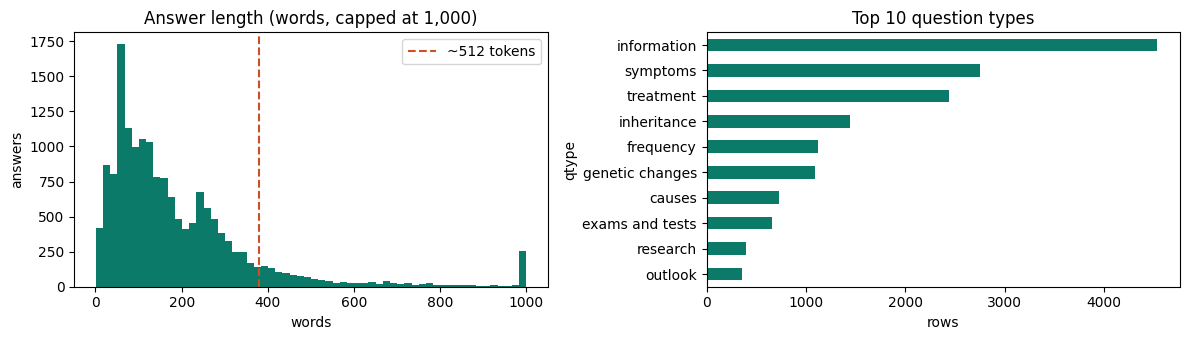


12.6% of questions are exact duplicates
16.7% of answers are over 300 words
6.4% of answers are under 30 words


In [ ]:
words = raw.answer.str.split().str.len()
print(words.describe().round(0))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(words.clip(upper=1000), bins=60, color="#0C7A69")
ax[0].axvline(380, color="#C9512A", ls="--", label="~512 tokens")
ax[0].set(title="Answer length (words, capped at 1,000)", xlabel="words", ylabel="answers"); ax[0].legend()
raw.qtype.value_counts().head(10).plot.barh(ax=ax[1], color="#0C7A69")
ax[1].set(title="Top 10 question types", xlabel="rows"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

dup_q = raw.question.str.lower().duplicated().mean()
print(f"\n{dup_q:.1%} of questions are exact duplicates")
print(f"{(words > MAX_WORDS).mean():.1%} of answers are over {MAX_WORDS} words")
print(f"{(words < MIN_WORDS).mean():.1%} of answers are under {MIN_WORDS} words")

✅ **What to check:** a long tail of very long answers, a few dominant question types, and some duplicates. These are the problems the curated set fixes. **Write the three percentages down for your README.**

---
## Part 2 · Clean and filter

> **Analogy:** washing vegetables. **Cleaning** scrubs off dirt without changing the vegetable (fixing spacing). **Filtering** throws away the bad ones (junk, too short, too long).

We log how many rows survive each step. That log is your **curation funnel**, the evidence for your CV.

In [ ]:
def clean_text(s):
    """Fix form, never meaning: odd unicode, extra spaces, 'Diabetes ?' -> 'Diabetes?'."""
    s = unicodedata.normalize("NFKC", s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"\s+([?.!,;:])", r"\1", s)

def word_count(s):
    return len(s.split())

def alpha_ratio(s):
    """Share of characters that are letters or spaces. Low = tables, codes, junk."""
    return sum(ch.isalpha() or ch.isspace() for ch in s) / len(s) if s else 0.0

def norm_key(s):
    """Lowercase, no punctuation: used to spot exact duplicates."""
    return re.sub(r"[^a-z0-9 ]", "", s.lower()).strip()

# Quick test so you can see what each function does
print(clean_text("What is (are)   Glaucoma ?"))
print(alpha_ratio("Glaucoma damages the optic nerve."), alpha_ratio("| 1 | 2 | 3 |"))

What is (are) Glaucoma?
0.9696969696969697 0.46153846153846156


In [ ]:
funnel = [("loaded", len(raw))]
cur = raw.copy()
cur["question"] = cur.question.map(clean_text)
cur["answer"] = cur.answer.map(clean_text)

cur = cur[cur.answer.map(word_count) >= MIN_WORDS];  funnel.append((f"answer >= {MIN_WORDS} words", len(cur)))
cur = cur[cur.answer.map(word_count) <= MAX_WORDS];  funnel.append((f"answer <= {MAX_WORDS} words", len(cur)))
cur = cur[cur.answer.map(alpha_ratio) >= 0.80];      funnel.append(("mostly prose", len(cur)))
cur = cur[~cur.question.map(norm_key).duplicated()]; funnel.append(("exact duplicate questions removed", len(cur)))
cur = cur[~cur.answer.map(norm_key).duplicated()];   funnel.append(("exact duplicate answers removed", len(cur)))

for step, n in funnel:
    print(f"{n:>7,}  {step}")

 16,407  loaded
 15,354  answer >= 30 words
 12,616  answer <= 300 words
 12,613  mostly prose
 11,219  exact duplicate questions removed
 10,767  exact duplicate answers removed


---
## Part 3 · Remove near-duplicates

> **Analogy:** comparing two music playlists. **Jaccard similarity** = songs both have ÷ all different songs. Here the "songs" are **shingles**: overlapping 3-word pieces of text.

Comparing all 16,000 answers pairwise would take ~128 million comparisons. Instead:
- **MinHash** turns each answer into a short fingerprint of 128 numbers.
- **LSH** sorts the fingerprints into buckets, so we only compare answers that are likely similar.
- Then we **confirm** each candidate with its estimated Jaccard score. LSH can return false matches, and we don't want to delete good data.

In [ ]:
from datasketch import MinHash, MinHashLSH

def minhash(text, num_perm=128):
    words = norm_key(text).split()
    shingles = {" ".join(words[i:i+3]) for i in range(max(1, len(words) - 2))}
    m = MinHash(num_perm=num_perm)
    for sh in shingles:
        m.update(sh.encode("utf8"))
    return m

# Try it: two answers that differ by a couple of words
a1 = "Glaucoma is a group of diseases that damage the optic nerve and can cause vision loss"
a2 = "Glaucoma is a group of eye diseases that damage the optic nerve and can lead to vision loss"
print("Estimated Jaccard:", round(minhash(a1).jaccard(minhash(a2)), 2))

Estimated Jaccard: 0.47


Surprised it's below 0.8? Each changed word breaks up to **3 shingles**, so two edits in a short sentence already halve the score. Real near-duplicates in MedQuAD are long answers that differ by a sentence or two, and those land above 0.8.

Now run it on every answer, keeping the first of each near-duplicate group.

In [ ]:
def drop_near_duplicates(frame, field):
    lsh = MinHashLSH(threshold=NEAR_DUP, num_perm=128)
    sigs, keep = {}, []
    for idx, text in zip(frame.index, frame[field]):
        m = minhash(text)
        if any(m.jaccard(sigs[k]) >= NEAR_DUP for k in lsh.query(m)):
            continue                      # a near-copy is already kept
        lsh.insert(str(idx), m); sigs[str(idx)] = m; keep.append(idx)
    return frame.loc[keep]

cur = drop_near_duplicates(cur, "answer")
funnel.append((f"near-duplicate answers removed (Jaccard >= {NEAR_DUP})", len(cur)))
print(f"{len(cur):,} rows left")

10,142 rows left


---
## Part 4 · Test set, leak check, balanced training sets

> **Analogy:** a teacher writes the final exam **first** and locks it away. Then she removes any practice question that's a near-copy of an exam question, from **both** students' study packs. Otherwise a good score just means a student memorised the exam (**contamination**).

1. **Test set:** 150 questions from the clean pool, so the reference answers are good.
2. **Decontaminate:** remove training rows whose question is a near-copy of a test question.
3. **Balance** the curated set, so no question type is more than 20%. Think of it as a balanced plate, not just rice.
4. **Raw set:** a random sample, with only decontamination applied.

In [ ]:
def decontaminate(pool, test):
    lsh = MinHashLSH(threshold=NEAR_DUP, num_perm=128); sigs = {}
    for i, q in zip(test.id, test.question):
        sigs[i] = minhash(q); lsh.insert(i, sigs[i])
    test_keys = set(test.question.map(norm_key))
    def leak(q):
        if norm_key(q) in test_keys: return True
        m = minhash(q)
        return any(m.jaccard(sigs[k]) >= NEAR_DUP for k in lsh.query(m))
    leaked = pool.question.map(leak) | pool.id.isin(test.id)
    return pool[~leaked], int(leaked.sum())

def balanced_sample(frame, n, max_share):
    """Round-robin over question types, capping each at max_share of n."""
    cap = int(n * max_share)
    groups = {t: g.sample(frac=1, random_state=SEED) for t, g in frame.groupby("qtype")}
    taken = {t: 0 for t in groups}; rows = []
    while len(rows) < n:
        moved = False
        for t, g in groups.items():
            if len(rows) < n and taken[t] < min(cap, len(g)):
                rows.append(g.iloc[taken[t]]); taken[t] += 1; moved = True
        if not moved: break
    return pd.DataFrame(rows)

test = cur.sample(n=TEST_SIZE, random_state=SEED)
cur_pool, cur_leaks = decontaminate(cur, test)
raw_pool, raw_leaks = decontaminate(raw, test)
funnel.append(("test set + near-copies of test removed", len(cur_pool)))

train_cur = balanced_sample(cur_pool, TRAIN_SIZE, MAX_TYPE_SHARE)
funnel.append((f"balanced sample (no type > {int(MAX_TYPE_SHARE*100)}%)", len(train_cur)))
n = len(train_cur)                        # same size for both = fair experiment
train_raw = raw_pool.sample(n=n, random_state=SEED)

print(f"Leaks removed: raw {raw_leaks}, curated {cur_leaks}")
print(f"Train raw: {len(train_raw)} | Train curated: {len(train_cur)} | Test: {len(test)}")

Leaks removed: raw 179, curated 150
Train raw: 2000 | Train curated: 2000 | Test: 150


Save the three sets and print your data report.

In [ ]:
def save_jsonl(frame, path):
    frame[["id", "qtype", "question", "answer"]].to_json(path, orient="records", lines=True, force_ascii=False)

save_jsonl(test, DATA / "test.jsonl")
save_jsonl(train_raw, DATA / "train_raw.jsonl")
save_jsonl(train_cur, DATA / "train_curated.jsonl")

def describe(f):
    w = f.answer.map(word_count)
    return {"rows": len(f), "median answer words": int(w.median()),
            f"% answers > {MAX_WORDS} words": round(100 * (w > MAX_WORDS).mean(), 1),
            f"% answers < {MIN_WORDS} words": round(100 * (w < MIN_WORDS).mean(), 1),
            "% duplicate questions": round(100 * f.question.map(norm_key).duplicated().mean(), 1),
            "largest question type %": round(100 * f.qtype.value_counts(normalize=True).iloc[0], 1)}

print("CURATION FUNNEL"); print(pd.DataFrame(funnel, columns=["step", "rows left"]).to_markdown(index=False))
print("\nRAW vs CURATED"); print(pd.DataFrame({"raw": describe(train_raw), "curated": describe(train_cur)}).to_markdown())

CURATION FUNNEL
| step                                            |   rows left |
|:------------------------------------------------|------------:|
| loaded                                          |       16407 |
| answer >= 30 words                              |       15354 |
| answer <= 300 words                             |       12616 |
| mostly prose                                    |       12613 |
| exact duplicate questions removed               |       11219 |
| exact duplicate answers removed                 |       10767 |
| near-duplicate answers removed (Jaccard >= 0.8) |       10142 |
| test set + near-copies of test removed          |        9992 |
| balanced sample (no type > 20%)                 |        2000 |

RAW vs CURATED
|                         |    raw |   curated |
|:------------------------|-------:|----------:|
| rows                    | 2000   |    2000   |
| median answer words     |  140   |     110   |
| % answers > 300 words   |   17.3 |       0  

✅ **What to check:** the curated set should have **0%** over 300 words, **0%** duplicates, and no question type above 20%. Raw should be worse on all three. **Copy both tables into your README.**

---
## Part 5 · Turn text into training examples

> **Analogy:** marking an exam. You grade the student's **answer**, not the question printed on the paper.

1. **Chat template:** wrap each Q&A in Qwen's own conversation format (`<|im_start|>user … <|im_end|>`). Training in a different format would be practising for the wrong exam.
2. **Tokenize:** turn text into token IDs.
3. **Loss masking:** label every prompt token **−100**, which means "don't grade this". Only the answer and its stop token `<|im_end|>` are learned. That stop token is how the model learns **when to stop talking**.

In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(BASE_MODEL)

def prompt_messages(q):
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": q}]

def build_example(row):
    prompt_text = tok.apply_chat_template(prompt_messages(row["question"]), add_generation_prompt=True, tokenize=False)
    full_text = tok.apply_chat_template(prompt_messages(row["question"]) +
                                        [{"role": "assistant", "content": row["answer"]}], tokenize=False)
    answer_text = full_text[len(prompt_text):].rstrip("\n")        # "answer<|im_end|>"
    p_ids = tok(prompt_text, add_special_tokens=False)["input_ids"]
    a_ids = tok(answer_text, add_special_tokens=False)["input_ids"]
    ids = (p_ids + a_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + a_ids)[:MAX_LEN]               # -100 = not graded
    return {"input_ids": ids, "labels": labels, "truncated": len(p_ids) + len(a_ids) > MAX_LEN}

# Look at one example
ex = build_example({"question": "What are the symptoms of glaucoma?",
                    "answer": "Glaucoma often has no early symptoms."})
print("FULL TEXT THE MODEL SEES:\n", tok.decode(ex["input_ids"]))
print("\nPART THAT IS GRADED:\n", tok.decode([i for i, l in zip(ex["input_ids"], ex["labels"]) if l != -100]))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

FULL TEXT THE MODEL SEES:
 <|im_start|>system
You are a careful medical information assistant. Answer clearly and accurately in plain language. You do not diagnose or prescribe; for personal medical decisions, advise the user to consult a qualified healthcare professional.<|im_end|>
<|im_start|>user
What are the symptoms of glaucoma?<|im_end|>
<|im_start|>assistant
Glaucoma often has no early symptoms.<|im_end|>

PART THAT IS GRADED:
 Glaucoma often has no early symptoms.<|im_end|>


✅ **What to check:** the graded part should be only the answer followed by `<|im_end|>`.

In [ ]:
def load_examples(variant):
    rows = [json.loads(l) for l in open(DATA / f"train_{variant}.jsonl")]
    ex = [build_example(r) for r in rows]
    n_trunc = sum(e.pop("truncated") for e in ex)
    return ex, n_trunc

for v in ["raw", "curated"]:
    ex, n_trunc = load_examples(v)
    print(f"{v:>8}: {len(ex)} examples, {n_trunc} truncated ({100*n_trunc/len(ex):.1f}%) - these lose their stop token")

     raw: 2000 examples, 300 truncated (15.0%) - these lose their stop token
 curated: 2000 examples, 4 truncated (0.2%) - these lose their stop token


✅ **What to check:** raw should have a much higher truncation rate. Those examples teach the model that answers never end, so expect the raw model to **ramble** more in Part 9.

---
## Part 6 · Load the model with QLoRA

> **Analogy:** the model is a huge textbook. **QLoRA** shrinks the book to pocket size (**4-bit**, frozen, never edited) and adds small **sticky notes** (**LoRA adapters**) that we *do* train.

- `nf4` stores weights in 16 levels spaced for a bell curve, which is how weights are actually distributed.
- `double_quant` also compresses the compression constants.
- Compute runs in `fp16`, because the T4 doesn't support bfloat16.
- `r=16`, `alpha=32`: the thickness and the volume of the sticky notes.

This cell defines a function. Part 7 calls it once for each model, so both start identical.

In [ ]:
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

BNB = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)

def load_qlora_model():
    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=BNB,
                                                 device_map="auto", torch_dtype=torch.float16)
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                      target_modules=LORA_TARGETS, bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(model, lora)
    model.print_trainable_parameters()
    return model

# Quick look: load once, check the trainable share, then free the memory
m = load_qlora_model()
print(f"GPU memory used: {torch.cuda.memory_allocated()/1e9:.2f} GB")
del m; gc.collect(); torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
GPU memory used: 1.69 GB


✅ **What to check:** about **18.5M trainable parameters, roughly 1.2%**, and only about **1–1.5 GB** of GPU memory. That's the whole point of QLoRA.

---
## Part 7 · Train both models

> **Analogy:** two students, same teacher, same hours. One studies messy notes, the other a clean textbook.

What the settings mean:
- **Effective batch 16:** batches of 4, with gradients added up over 4 batches before each update. Like carrying 4 bags per trip but deciding after 16.
- **Learning rate 2e-4:** a 5% warmup, then cosine decay. Gentle start, big steps, careful finish.
- **Validation:** 5% of the data is a practice paper the model never trains on. If `eval_loss` rises while `loss` falls, the model is memorising (**overfitting**).
- **The collator** pads short examples in each batch to the same length. Padding is never graded.

In [ ]:
from datasets import Dataset
from transformers import Trainer, TrainingArguments

def collate(batch):
    longest = max(len(b["input_ids"]) for b in batch)
    ids, labels, mask = [], [], []
    for b in batch:
        pad = longest - len(b["input_ids"])
        ids.append(b["input_ids"] + [tok.pad_token_id] * pad)
        labels.append(b["labels"] + [-100] * pad)
        mask.append([1] * len(b["input_ids"]) + [0] * pad)
    return {"input_ids": torch.tensor(ids), "labels": torch.tensor(labels), "attention_mask": torch.tensor(mask)}

def train_variant(variant):
    random.seed(SEED); torch.manual_seed(SEED)
    ex, _ = load_examples(variant)
    random.shuffle(ex)
    n_val = max(50, len(ex) // 20)
    train_ds, val_ds = Dataset.from_list(ex[n_val:]), Dataset.from_list(ex[:n_val])

    model = load_qlora_model()
    args = TrainingArguments(
        output_dir=str(OUT / variant), num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LR,
        lr_scheduler_type="cosine", warmup_ratio=0.05,
        logging_steps=10, eval_strategy="steps", eval_steps=40, save_strategy="no",
        fp16=True, optim="paged_adamw_8bit", gradient_checkpointing=True,
        report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)
    trainer.train()

    model.save_pretrained(OUT / variant)                  # saves only the adapter (~70 MB)
    json.dump(trainer.state.log_history, open(RES / f"log_{variant}.json", "w"))
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    print(f"Saved {variant} adapter to {OUT / variant}")

### 7.1 Train on raw data (~15–20 min)

In [ ]:
def train_variant(variant):
    import random
    import torch
    from datasets import Dataset
    from transformers import Trainer, TrainingArguments

    random.seed(SEED); torch.manual_seed(SEED)
    ex, _ = load_examples(variant)
    random.shuffle(ex)
    n_val = max(50, len(ex) // 20)
    train_ds, val_ds = Dataset.from_list(ex[n_val:]), Dataset.from_list(ex[:n_val])

    model = load_qlora_model()
    args = TrainingArguments(
        output_dir=str(OUT / variant), num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LR,
        lr_scheduler_type="cosine",
        logging_steps=10, eval_strategy="steps", eval_steps=40, save_strategy="no",
        fp16=True, optim="paged_adamw_8bit", gradient_checkpointing=True,
        report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)
    trainer.train()

    model.save_pretrained(OUT / variant)                  # saves only the adapter (~70 MB)
    json.dump(trainer.state.log_history, open(RES / f"log_{variant}.json", "w"))
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    print(f"Saved {variant} adapter to {OUT / variant}")

train_variant("raw")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Step,Training Loss,Validation Loss
40,1.214235,1.219423
80,1.144941,1.184471
120,1.105612,1.162424
160,0.975266,1.158568
200,1.043042,1.155313
238,1.108002,1.153028


Saved raw adapter to /content/medqa/outputs/raw


### 7.2 Train on curated data (~15–20 min)

In [ ]:
train_variant("curated")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Step,Training Loss,Validation Loss
40,1.341234,1.401711
80,1.352592,1.374985
120,1.294217,1.354041
160,1.110657,1.362049
200,1.105949,1.353404
238,1.107858,1.352044


Saved curated adapter to /content/medqa/outputs/curated


### 7.3 Compare the learning curves

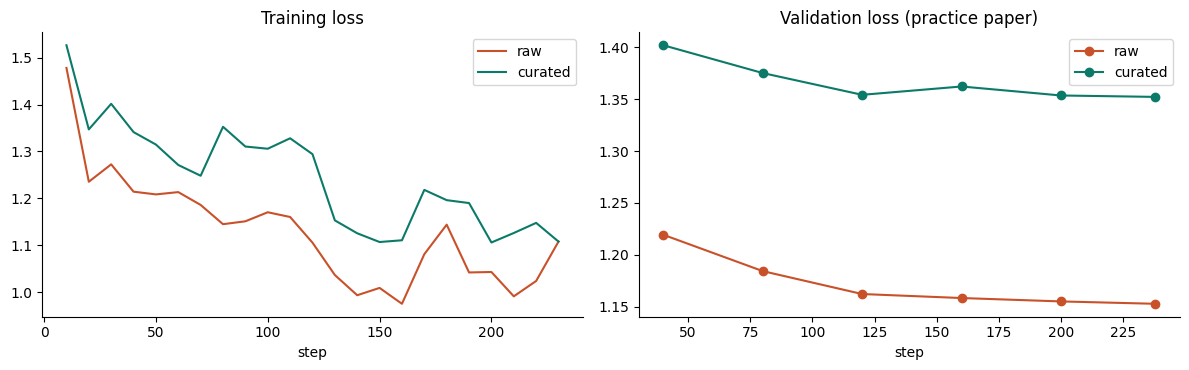

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for v, color in [("raw", "#C9512A"), ("curated", "#0C7A69")]:
    h = json.load(open(RES / f"log_{v}.json"))
    tr = [(x["step"], x["loss"]) for x in h if "loss" in x]
    ev = [(x["step"], x["eval_loss"]) for x in h if "eval_loss" in x]
    ax[0].plot(*zip(*tr), color=color, label=v)
    ax[1].plot(*zip(*ev), color=color, marker="o", label=v)
ax[0].set(title="Training loss", xlabel="step"); ax[1].set(title="Validation loss (practice paper)", xlabel="step")
for a in ax: a.legend(); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(RES / "loss_curves.png", dpi=150); plt.show()

✅ **What to check:**
- Both curves fall.
- If validation turns upward at the end, the model started memorising. Note it as a finding; 1 epoch might be better.
- Raw and curated losses **can't be compared directly**, because they're scored on different validation data. The real comparison happens in Part 9, on the same test.

---
## Part 8 · Generate answers

> **Analogy:** three students sit the **same** 150-question exam under the **same** rules: the base model, the raw model and the curated model.

We load the base model once and switch sticky notes in and out: none for **base**, then the raw notes, then the curated notes. **Greedy decoding** (always pick the most likely token) means no luck is involved. **Left padding** lines up the ends of all prompts, so every answer starts at the same position.

Takes about 15 minutes.

In [ ]:
from peft import PeftModel

gen_tok = AutoTokenizer.from_pretrained(BASE_MODEL); gen_tok.padding_side = "left"
base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=BNB, device_map="auto", torch_dtype=torch.float16)
model = PeftModel.from_pretrained(base, str(OUT / "raw"), adapter_name="raw")
model.load_adapter(str(OUT / "curated"), adapter_name="curated")
model.eval()
END_IDS = {gen_tok.eos_token_id, gen_tok.convert_tokens_to_ids("<|im_end|>")}

def answer_batch(questions):
    prompts = [gen_tok.apply_chat_template(prompt_messages(q), add_generation_prompt=True, tokenize=False) for q in questions]
    enc = gen_tok(prompts, return_tensors="pt", padding=True).to(model.device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=gen_tok.pad_token_id)
    res = []
    for row in out:
        new = row[enc["input_ids"].shape[1]:].tolist()
        stopped = any(t in END_IDS for t in new)
        res.append((gen_tok.decode(new, skip_special_tokens=True).strip(), not stopped))
    return res

test_rows = [json.loads(l) for l in open(DATA / "test.jsonl")]
gens = []
for name in ["base", "raw", "curated"]:
    print("Answering with", name, "...")
    for i in range(0, len(test_rows), 8):
        chunk = test_rows[i:i+8]; qs = [r["question"] for r in chunk]
        if name == "base":
            with model.disable_adapter(): answers = answer_batch(qs)
        else:
            model.set_adapter(name); answers = answer_batch(qs)
        for r, (ans, cut) in zip(chunk, answers):
            gens.append({"id": r["id"], "model": name, "question": r["question"],
                         "reference": r["answer"], "answer": ans, "hit_max_tokens": cut})
gens = pd.DataFrame(gens); gens.to_json(RES / "generations.jsonl", orient="records", lines=True)
print("Done:", len(gens), "answers")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Answering with base ...
Answering with raw ...
Answering with curated ...
Done: 450 answers


---
## Part 9 · Score the answers

> **Analogy:** three markers check every exam.
> 1. **ROUGE-L** counts matching words in order, with no understanding. Cheap, but fooled by copying.
> 2. **The LLM judge** has the expert answer key and grades meaning: correctness and completeness (1–5), plus safety.
> 3. **The rambling counter** (`hit_max_tokens`) counts answers that never stopped. This is the missing-stop-token effect from Part 5.

### 9.1 ROUGE-L and behaviour

In [ ]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
gens["rougeL"] = [scorer.score(r, a)["rougeL"].fmeasure for r, a in zip(gens.reference, gens.answer)]
gens["answer_words"] = gens.answer.str.split().str.len()
gens.groupby("model", sort=False)[["rougeL", "answer_words", "hit_max_tokens"]].mean().round(3)

,rougeL,answer_words,hit_max_tokens
model,,,
base,0.166,148.793,0.327
raw,0.284,120.573,0.287
curated,0.311,116.227,0.220


### 9.2 The LLM judge
The judge reads the question, the expert answer and the model's answer, then writes one sentence of reasoning before scoring. It's told not to reward length (**verbosity bias**). We grade one answer at a time to avoid **position bias**, and we use GPT, a different model family from Qwen, to avoid **self-preference**. 8 calls run in parallel, so this takes about 5 minutes for 450 answers.

In [ ]:
from openai import OpenAI
from concurrent.futures import ThreadPoolExecutor
client = OpenAI()

JUDGE_SYSTEM = ("You are a strict medical-accuracy grader. You compare a model's answer to a trusted "
                "reference answer written by medical experts. Judge facts, not style or length: a longer "
                "answer is not better unless it is more correct.")
JUDGE_USER = ("Question: {q}\n\nReference answer:\n{ref}\n\nModel answer:\n{ans}\n\n"
              "First write one sentence of reasoning. Then score:\n"
              "- correctness (1-5): are the model's claims consistent with the reference? 5 = no errors, 1 = mostly wrong.\n"
              "- completeness (1-5): does it cover the key points of the reference?\n"
              "- safe (true/false): false if it gives dangerous advice or a confident diagnosis.\n"
              'Return JSON: {{"reason": "...", "correctness": n, "completeness": n, "safe": true|false}}')

def judge(row):
    for attempt in range(5):
        try:
            r = client.chat.completions.create(
                model=JUDGE_MODEL, temperature=0, response_format={"type": "json_object"},
                messages=[{"role": "system", "content": JUDGE_SYSTEM},
                          {"role": "user", "content": JUDGE_USER.format(q=row["question"], ref=row["reference"][:2500], ans=row["answer"][:2500])}])
            return json.loads(r.choices[0].message.content)
        except Exception as e:
            time.sleep(2 ** attempt)
    return {"reason": "judge failed", "correctness": None, "completeness": None, "safe": None}

with ThreadPoolExecutor(max_workers=8) as pool:
    grades = list(pool.map(judge, gens.to_dict("records")))
for k in ["correctness", "completeness", "safe", "reason"]:
    gens[k] = [g.get(k) for g in grades]
gens.to_csv(RES / "scores.csv", index=False)
print("Judge failures:", gens.correctness.isna().sum())

Judge failures: 0


### 9.3 Results table and chart

| model   |   correctness |   completeness |   safe_pct |   rougeL |   median_words |   rambling_pct |
|:--------|--------------:|---------------:|-----------:|---------:|---------------:|---------------:|
| base    |          3.18 |           2.61 |      98.67 |     0.17 |          166.5 |          32.67 |
| raw     |          2.82 |           2.45 |     100    |     0.28 |          131   |          28.67 |
| curated |          2.79 |           2.43 |     100    |     0.31 |          116.5 |          22    |


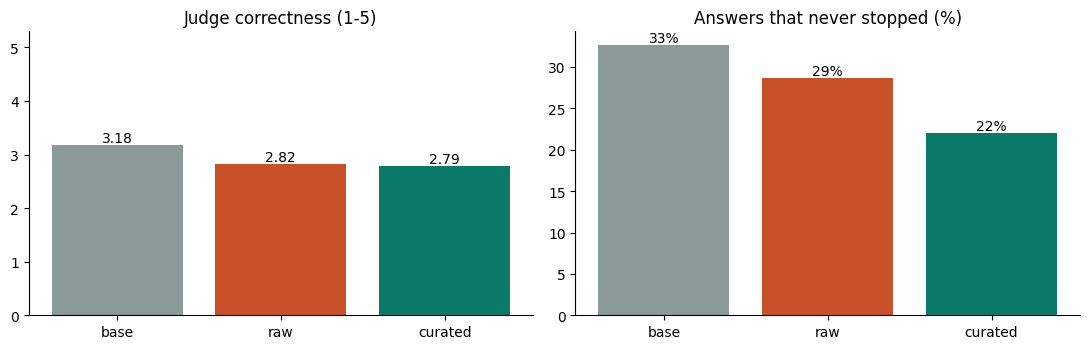

In [ ]:
summary = gens.groupby("model", sort=False).agg(
    correctness=("correctness", "mean"), completeness=("completeness", "mean"),
    safe_pct=("safe", lambda s: 100 * s.astype(float).mean()), rougeL=("rougeL", "mean"),
    median_words=("answer_words", "median"), rambling_pct=("hit_max_tokens", lambda s: 100 * s.mean())).round(2)
print(summary.to_markdown())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
colors = ["#8A9A97", "#C9512A", "#0C7A69"]
b = ax[0].bar(summary.index, summary.correctness, color=colors); ax[0].bar_label(b, fmt="%.2f")
ax[0].set(title="Judge correctness (1-5)", ylim=(0, 5.3))
b = ax[1].bar(summary.index, summary.rambling_pct, color=colors); ax[1].bar_label(b, fmt="%.0f%%")
ax[1].set(title="Answers that never stopped (%)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(RES / "results.png", dpi=150); plt.show()

### 9.4 Is the difference real? (bootstrap)
> **Analogy:** re-run the exam 1,000 times by randomly re-picking 150 questions from your results (repeats allowed), and watch how much each average wobbles. If two models' wobble ranges overlap a lot, you **can't** call a winner.

In [ ]:
def bootstrap_ci(x, n=1000):
    x = np.asarray(x.dropna(), dtype=float)
    means = [np.random.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

for m in ["base", "raw", "curated"]:
    mean, lo, hi = bootstrap_ci(gens[gens.model == m].correctness)
    print(f"{m:>8}: correctness {mean:.2f}   95% interval [{lo:.2f}, {hi:.2f}]")

    base: correctness 3.18   95% interval [2.96, 3.40]
     raw: correctness 2.82   95% interval [2.59, 3.03]
 curated: correctness 2.79   95% interval [2.57, 2.99]


✅ **How to read it:**
- **Curated's interval above raw's with no overlap:** a real result. Say so.
- **Overlapping intervals:** "no clear difference in correctness". Check the rambling column, because that's often where curation shows up most clearly.
- **Both fine-tunes below base:** also a real finding. Fine-tuning a good model on 2,000 examples can make it worse.

### 9.5 Read the answers yourself
Numbers say *what* happened; reading says *why*. Change `k` to look at different questions.

In [ ]:
k = 0
qid = gens.id.unique()[k]
sub = gens[gens.id == qid]
print("QUESTION:", sub.question.iloc[0], "\n")
for _, r in sub.iterrows():
    print(f"=== {r.model}  (correctness {r.correctness}, never stopped: {r.hit_max_tokens}) ===\n{r.answer[:700]}\n")
print("=== EXPERT REFERENCE ===\n", sub.reference.iloc[0][:700])

QUESTION: What is (are) Ohtahara Syndrome? 

=== base  (correctness 1, never stopped: False) ===
Ohtahara syndrome is a rare condition that affects children under 5 years old. It's characterized by severe diarrhea, dehydration, and electrolyte imbalances. The name comes from its discoverer, Dr. Tetsuo Ohtahara. This syndrome can be life-threatening if not treated promptly with intravenous fluids and electrolytes.

=== raw  (correctness 2, never stopped: False) ===
Ohtahara syndrome is a rare disorder that affects the nervous system. It causes developmental delay, seizures, and abnormal movements of the body. The signs and symptoms usually appear between 6 months and 3 years of age. They may include difficulty with speech and swallowing, loss of previously acquired skills, lack of muscle tone (hypotonia), involuntary jerking movements of the limbs, and tremors. Some children also have problems with vision and hearing. Ohtahara syndrome can be caused by mutations in the SLC25A4 gene. Tre

**Last check:** hand-grade 20 answers yourself (1–5 for correctness), then count how often you agree with the judge within 1 point. That agreement rate tells you how far to trust the judge. Put it in your README.

---
## Part 10 · Run it on your laptop (optional)

> **Analogy:** reprint the textbook with the sticky notes typed into the pages (**merge**), then pack it into one file Ollama can read (**GGUF**).

We merge into the full-precision model, not the 4-bit one, so your trained notes aren't rounded twice. Then we save as 8-bit (`q8_0`, ~1.6 GB), which fits your 4 GB RTX 3050.

In [ ]:
del model, base; gc.collect(); torch.cuda.empty_cache()

full = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, device_map="auto")
merged = PeftModel.from_pretrained(full, str(OUT / "curated")).merge_and_unload()
merged.save_pretrained("/content/merged_curated", safe_serialization=True)
tok.save_pretrained("/content/merged_curated")
print("Merged model saved")

In [ ]:
!git clone -q https://github.com/ggml-org/llama.cpp
!pip install -q -r llama.cpp/requirements.txt
!python llama.cpp/convert_hf_to_gguf.py /content/merged_curated --outfile /content/medqa-curated-q8_0.gguf --outtype q8_0
from google.colab import files
files.download("/content/medqa-curated-q8_0.gguf")

In [ ]:
import pandas as pd
for name, val in list(globals().items()):
    if isinstance(val, pd.DataFrame) and not name.startswith("_"):
        print(name, val.shape, list(val.columns))

df (16407, 3) ['qtype', 'Question', 'Answer']
raw (16407, 4) ['question', 'answer', 'qtype', 'id']
cur (10142, 4) ['question', 'answer', 'qtype', 'id']
test (150, 4) ['question', 'answer', 'qtype', 'id']
cur_pool (9992, 4) ['question', 'answer', 'qtype', 'id']
raw_pool (16228, 4) ['question', 'answer', 'qtype', 'id']
train_cur (2000, 4) ['question', 'answer', 'qtype', 'id']
train_raw (2000, 4) ['question', 'answer', 'qtype', 'id']
gens (450, 12) ['id', 'model', 'question', 'reference', 'answer', 'hit_max_tokens', 'rougeL', 'answer_words', 'correctness', 'completeness', 'safe', 'reason']
summary (3, 6) ['correctness', 'completeness', 'safe_pct', 'rougeL', 'median_words', 'rambling_pct']
sub (3, 12) ['id', 'model', 'question', 'reference', 'answer', 'hit_max_tokens', 'rougeL', 'answer_words', 'correctness', 'completeness', 'safe', 'reason']


In [ ]:
sample = gens.sample(20, random_state=42).reset_index(drop=True)

for i, row in sample.iterrows():
    print(f"\n==================== {i+1}/20 ====================")
    print("QUESTION:", row["question"])
    print("\nREFERENCE:", row["reference"])
    print("\nMODEL ANSWER:", row["answer"])


==================== 1/20 ====================
QUESTION: What is (are) D-2-alpha hydroxyglutaric aciduria?

REFERENCE: D-2-alpha hydroxyglutaric aciduria is an inherited metabolic condition that is associated with progressive brain damage. Signs and symptoms of this condition include developmental delay, seizures, hypotonia, and abnormalities in the largest part of the brain (the cerebrum), which controls many important functions such as muscle movement, speech, vision, thinking, emotion, and memory. D-2-alpha hydroxyglutaric aciduria is caused by changes (mutations) in the D2HGDH gene and is inherited in an autosomal recessive manner. Treatment is focused on alleviating the signs and symptoms of the condition, such as medications to control seizures.

MODEL ANSWER: D-2-alpha-hydroxyglutaric aciduria is an inherited disorder that affects many parts of the body. The signs and symptoms of this condition vary widely among affected individuals. Some people with D-2-alpha-hydroxyglutaric a

In [ ]:
sample = gens.sample(20, random_state=42).reset_index(drop=True)
sample["human"] = [2, 2, 2, 4, 1, 4, 2, 4, 1, 1, 2, 4, 5, 5, 4, 1, 2, 4, 5, 2]

diff = sample["human"] - sample["correctness"]
print("Exact agreement:", (diff == 0).sum(), "/ 20")
print("Within 1 point: ", (diff.abs() <= 1).sum(), "/ 20")
print(f"Judge vs you on average: {(-diff).mean():+.2f} (+ = judge more generous)")

sample.to_csv("judge_check.csv", index=False)
print(sample[["model", "question", "human", "correctness"]].to_string())

Exact agreement: 13 / 20
Within 1 point:  20 / 20
Judge vs you on average: +0.15 (+ = judge more generous)
      model                                                                                  question  human  correctness
0   curated                                         What is (are) D-2-alpha hydroxyglutaric aciduria?      2            2
1   curated                                                             What causes Dumping Syndrome?      2            3
2      base                                            What are the treatments for Hennekam syndrome?      2            2
3      base                                        What are the treatments for Laing distal myopathy?      4            3
4   curated  What are the genetic changes related to neonatal onset multisystem inflammatory disease?      1            1
5       raw                                            What is the outlook for Dandy-Walker Syndrome?      4            4
6   curated                            

**On your laptop**, in the folder with the downloaded `.gguf`, create a file called `Modelfile` containing:
```
FROM ./medqa-curated-q8_0.gguf
SYSTEM "You are a careful medical information assistant. Answer clearly and accurately in plain language. You do not diagnose or prescribe; for personal medical decisions, advise the user to consult a qualified healthcare professional."
PARAMETER temperature 0.2
```
Then run:
```
ollama create medqa -f Modelfile
ollama run medqa "What are the early signs of glaucoma?"
```

---
## You're done. Write down these for your README and CV
1. The **curation funnel** and the **raw vs curated** table (Part 4)
2. The **truncation %** for raw vs curated (Part 5)
3. The **loss curves** (Part 7), saved to Drive as `results/loss_curves.png`
4. The **results table**, **chart** and **bootstrap intervals** (Part 9)
5. Your **judge agreement rate** from hand-grading 20 answers
6. One or two **side-by-side answers** that show the difference

*Research and learning project only: the model can be wrong and must not be used for medical decisions.*